# 01 — Cleaning: D3 college golf hole-by-hole data

**Purpose.** Turn `data/raw/d3_data.csv` into a hole-by-hole dataset that is fit for a
hot-hand / cold-hand study in the style of Elmore & Urbaczewski (2018), *Hot and Cold Hands on
the PGA Tour: Do they Exist?* (`references/`). This notebook does no modelling. It produces
the clean tables that `02_momentum_analysis.ipynb` reads.

**Why cleaning matters more than usual for a momentum study.** The outcome of interest is the
dependence between *consecutive* holes. The most common corruptions in this file are exactly the
ones that manufacture that dependence: a nine-hole total typed as nine identical hole scores, an
event entered as round totals spread across holes, the same card entered twice. Each of these
creates artificial runs of identical results. A cleaning rule that lets them through would bias
the study toward finding momentum; a rule that also removes genuine streaks biases it against.
Both directions are reported below.

**Unit of cleaning: the round.** The raw file has exactly 18 rows per player-round. A round is
kept or dropped whole, because the analysis needs complete, ordered sequences of holes.
Dropping single bad holes would leave 4-, 9- and 17-hole fragments and break the sequence.

**Scope: everything.** Men and women, tournaments and qualifiers are cleaned with the same
rules. Scope (gender, tournament level, minimum rounds per player) is an analysis decision and
is set in the analysis notebook.

**Outputs** (`data/clean/`)

| file | grain | contents |
|---|---|---|
| `d3_clean_holes.parquet` | one row per hole | rounds that passed every check; always 18 rows per round |
| `d3_clean_rounds.parquet` | one row per round | round totals for the same rounds |
| `d3_round_audit.parquet` | one row per **raw** round | `status` = `kept` or the reason it was dropped, plus diagnostics |
| `d3_cleaning_summary.csv` | one row per reason | the drop table |

**How the checks are layered**

1. **Structure**: the raw file is what we think it is.
2. **Card checks**: what one scorecard can show (unscored holes, summary rows, placeholder and
   impossible scores, half-cards filled in from a total).
3. **Field checks**: what only the rest of the field can show (two courses under one hole
   number, pars that do not match the scores, fabricated events).
4. **Duplicate checks**: the same card entered twice, within or across events.

Each rule is stated, the evidence for it is shown, and the section ends with tests. A failed
test stops the notebook.

## 0. Configuration

Every threshold used below is declared here and nowhere else.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import binomtest, norm

# ---- files (works whether the kernel starts in the project root or in notebooks/) ----
ROOT        = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_PATH    = ROOT / "data" / "raw" / "d3_data.csv"
CLEAN_DIR   = ROOT / "data" / "clean"
OUT_HOLES   = CLEAN_DIR / "d3_clean_holes.parquet"
OUT_ROUNDS  = CLEAN_DIR / "d3_clean_rounds.parquet"
OUT_AUDIT   = CLEAN_DIR / "d3_round_audit.parquet"
OUT_SUMMARY = CLEAN_DIR / "d3_cleaning_summary.csv"
CLEAN_DIR.mkdir(parents=True, exist_ok=True)

# ---- keys ----
ROUND_KEYS = ["tournament_id", "round_number", "player_id"]   # one player's round
FIELD_KEYS = ["tournament_id", "round_number", "layout_id"]   # everyone on the same course that day
N_HOLES    = 18

# ---- card checks ----
VALID_PARS       = (3, 4, 5, 6)
PAR6_MIN_YARDS   = 550     # a par 6 is only believed on a hole at least this long
MAX_OVER_PAR     = 15      # a single hole cannot exceed par + this
FLAT_NINE_LEN    = 9       # a whole nine (holes 1-9 or 10-18) of identical scores ...
FLAT_RUN_ANY_LEN = 12      # ... or a run this long anywhere on the card ...
FLAT_RUN_MIN_OFF = 3       # ... containing this many non-par holes is a total spread across holes

# ---- field checks ----
MIN_FIELD            = 4      # fewer players than this on a course and its pars cannot be verified
PAR_RESPONSE_REF_MIN = 50     # fields this large define what genuine par response looks like
PAR_RESPONSE_Z       = 3.29   # flag a field whose par response is this many null SDs low (one-sided p = 0.0005)
FABRICATED_MEAN_RUN  = 5.0    # field-average longest run of identical scores (normal is about 3)
SALVAGE_SCHOOL_MIN_PLAYERS = 4     # a school needs this many players to be judged on its own
SALVAGE_SCHOOL_MIN_CORR    = 0.55  # school hole-means vs par: right course ~0.8, wrong course ~0
SALVAGE_MIN_KEPT           = 10    # a rescued half-field must still have this many players
SALVAGE_MIN_SEPARATION     = 0.30  # gap required between the lowest kept and highest dropped school

# ---- value repairs (the row is kept, the value is fixed or blanked) ----
YARDAGE_BOUNDS = {3: (70, 300), 4: (180, 560), 5: (200, 720), 6: (PAR6_MIN_YARDS, 800)}

# ---- kept but labelled ----
EXTREME_ROUND_MEDIAN_TO_PAR = 5    # is_extreme_round: median hole is +5 or worse (real, but an outlier)
MATCH_NAME_PATTERN = (r"\bvs\.?\b|\bv\.\s|\bdual\b|\bduel\b|tri[- ]?match|\bquad\b|\bmatch(?:es)?\b")

# ---- plotting ----
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": "#52514e", "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 9.5, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False, "legend.fontsize": 9, "figure.dpi": 110,
})

# ---- tests ----
TESTS = []

def check(name, passed, detail=""):
    "Record a test. A failure stops the notebook."
    passed = bool(passed)
    TESTS.append({"test": name, "passed": passed, "detail": detail})
    print(f"[{'PASS' if passed else 'FAIL'}] {name}" + (f"  ({detail})" if detail else ""))
    assert passed, f"TEST FAILED: {name}  {detail}"

pd.set_option("display.width", 200, "display.max_columns", 40, "display.max_colwidth", 46)

## 1. Load and verify the structure

Everything downstream relies on one structural fact: **each player-round is exactly 18 rows,
holes 1 to 18**. If that holds, the file reshapes into one scorecard per row (`rounds x 18`
matrices of score, par and yardage), and every card-level rule becomes an array operation.

**What the file does not contain: the order of play.** There is no starting hole or tee time.
College events commonly use two-tee and shotgun starts, so `hole_number` is the hole on the
card, not the order in which it was played. The paper handled this by working out each
player's starting tee by hand. That is not possible here, so the analysis notebook treats it as
a design question (which hole-to-hole transitions are trustworthy) rather than a cleaning one.

In [2]:
raw = pd.read_csv(RAW_PATH, low_memory=False, dtype={"course_id": "string"})
n_raw_rows = len(raw)

raw = raw.sort_values(ROUND_KEYS + ["hole_number"], kind="stable").reset_index(drop=True)

check("raw row count is a multiple of 18", n_raw_rows % N_HOLES == 0, f"{n_raw_rows:,} rows")
check("every round is holes 1..18 in order",
      (raw["hole_number"].to_numpy().reshape(-1, N_HOLES) == np.arange(1, N_HOLES + 1)).all())
check("no missing values in key or score columns",
      raw[ROUND_KEYS + ["hole_number", "par", "score", "to_par", "yardage",
                        "team_gender", "tournament_level", "school_id"]].notna().all().all())
check("to_par == score - par on every row", (raw["score"] - raw["par"] == raw["to_par"]).all())

# one row per round (first of each block of 18) + the scorecard matrices
META = ["tournament_id", "round_number", "player_id", "tournament_name", "tournament_level",
        "tournament_start_date", "tournament_end_date", "round_date", "team_gender",
        "school_id", "school_name", "player_name", "course_id"]
rounds = raw.iloc[::N_HOLES][META].reset_index(drop=True)
S = raw["score"].to_numpy().reshape(-1, N_HOLES)      # scores
P = raw["par"].to_numpy().reshape(-1, N_HOLES)        # pars
Y = raw["yardage"].to_numpy().reshape(-1, N_HOLES)    # yardages
n_raw_rounds = len(rounds)

check("round key (tournament, round, player) is unique", not rounds.duplicated(ROUND_KEYS).any(),
      f"{n_raw_rounds:,} rounds")
const_cols = [c for c in META if c not in ROUND_KEYS]
check("every round-level column is constant within a round (safe to read from hole 1)",
      (raw[const_cols].fillna("<NA>").astype(str).groupby(np.repeat(np.arange(n_raw_rounds), N_HOLES))
       .nunique() == 1).all().all())
check("no tournament mixes genders",
      (rounds.groupby("tournament_id")["team_gender"].nunique() == 1).all())

rounds["segment"] = rounds["team_gender"] + " " + rounds["tournament_level"].str.title()
print()
print(rounds.groupby(["team_gender", "tournament_level"]).size().rename("raw rounds").to_frame().T.to_string())

[PASS] raw row count is a multiple of 18  (3,034,656 rows)
[PASS] every round is holes 1..18 in order
[PASS] no missing values in key or score columns
[PASS] to_par == score - par on every row
[PASS] round key (tournament, round, player) is unique  (168,592 rounds)


[PASS] every round-level column is constant within a round (safe to read from hole 1)
[PASS] no tournament mixes genders

team_gender             Men                 Women           
tournament_level QUALIFYING TOURNAMENT QUALIFYING TOURNAMENT
raw rounds             2053     104468        747      61324


## 2. Card checks: what a single scorecard can tell us

| reason | rule | what it is |
|---|---|---|
| `no_card` | all 18 holes are 0 | did not start / no card returned |
| `nine_hole_round` | exactly one nine is scored | a round shortened to 9 holes |
| `incomplete_card` | any other 0 | withdrew mid-round or a hole was never entered |
| `invalid_par` | a par outside 3–6, or a par 6 shorter than 550 yards | a summary row (for example the front-nine total) in a hole slot |
| `placeholder_card` | two or more 1s, or all 18 scores identical | `1 1 1 … 1 <total>` and `5 5 5 … 5` cards |
| `impossible_score` | a hole above par + 15, or a 1 on a par 4 or longer | a total or a typo in a hole slot |

A score of 0 is never a real score. A real par 6 exists in this data (638 yards, field average
5.9), so par 6 is allowed when the hole is long enough. A hole-in-one on a par 4 is not strictly
impossible, but it is rarer than the typing errors that produce a `1` in that slot.

In [3]:
unscored   = (S == 0).sum(axis=1)
front_only = (S[:, :9] > 0).all(axis=1) & (S[:, 9:] == 0).all(axis=1)
back_only  = (S[:, :9] == 0).all(axis=1) & (S[:, 9:] > 0).all(axis=1)

par_ok   = np.isin(P, VALID_PARS) & ~((P == 6) & (Y < PAR6_MIN_YARDS))
n_ones   = (S == 1).sum(axis=1)
all_same = (S == S[:, [0]]).all(axis=1)

flag = pd.DataFrame(index=rounds.index)
flag["no_card"]          = unscored == N_HOLES
flag["nine_hole_round"]  = front_only | back_only
flag["incomplete_card"]  = (unscored > 0) & ~flag["no_card"] & ~flag["nine_hole_round"]
flag["invalid_par"]      = ~par_ok.all(axis=1)
flag["placeholder_card"] = (n_ones >= 2) | (all_same & (unscored == 0))
flag["impossible_score"] = ((S > P + MAX_OVER_PAR) | ((S == 1) & (P >= 4))).any(axis=1)

CARD_REASONS = list(flag.columns)
card_ok = ~flag[CARD_REASONS].any(axis=1).to_numpy()
rounds["unscored_holes"] = unscored

print("Rounds failing each card check (a round can fail more than one):")
print(flag[CARD_REASONS].groupby(rounds["segment"]).sum().T.assign(total=flag[CARD_REASONS].sum()).to_string())
print(f"\nRounds with a complete, plausible card: {card_ok.sum():,} of {n_raw_rounds:,}")

def show_cards(idx, title, n=6):
    "Print raw scorecards (scores | pars) for a handful of rounds."
    print(f"\n{title}")
    for i in list(idx)[:n]:
        print(f"  {str(rounds.at[i, 'tournament_name'])[:34]:34s} {str(rounds.at[i, 'player_name'])[:14]:14s} "
              + " ".join(f"{v:>2d}" for v in S[i]) + "  | par " + " ".join(str(v) for v in P[i]))

show_cards(rounds.index[flag["placeholder_card"] & (unscored == 0)], "placeholder_card examples:")
show_cards(rounds.index[flag["invalid_par"] & (unscored == 0)], "invalid_par examples (hole 18 holds the front-nine total):", 3)
show_cards(rounds.index[flag["impossible_score"] & ~flag["placeholder_card"] & ~flag["invalid_par"]],
           "impossible_score examples:", 4)

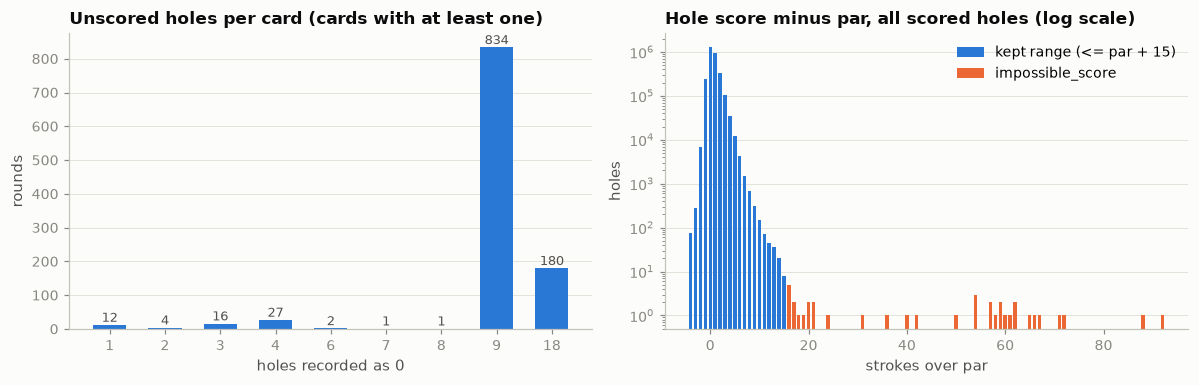

nine-hole rounds: 823 rounds in 39 tournament-rounds; in 35 of those the whole field played nine holes (a shortened round, not withdrawals).
[PASS] card reasons cover every card with an unscored hole
[PASS] every surviving card has 18 scored holes with par 3-6 and score in [1, par+15]


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

ax = axes[0]
vc = pd.Series(unscored).value_counts().sort_index()
vc = vc[vc.index > 0]
ax.bar(vc.index.astype(str), vc.values, color=BLUE, width=0.6)
for x, v in zip(vc.index.astype(str), vc.values):
    ax.text(x, v, f"{v:,}", ha="center", va="bottom", fontsize=8.5, color="#52514e")
ax.set_title("Unscored holes per card (cards with at least one)")
ax.set_xlabel("holes recorded as 0"); ax.set_ylabel("rounds"); ax.grid(axis="x", visible=False)

ax = axes[1]
ok_par = np.isin(P, (3, 4, 5, 6)) & (S > 0)
d = pd.Series((S - P)[ok_par]).value_counts().sort_index()
inside = (d.index <= MAX_OVER_PAR)
ax.bar(d.index[inside], d.values[inside], color=BLUE, width=0.7, label=f"kept range (<= par + {MAX_OVER_PAR})")
ax.bar(d.index[~inside], d.values[~inside], color=ORANGE, width=0.7, label="impossible_score")
ax.set_yscale("log"); ax.set_title("Hole score minus par, all scored holes (log scale)")
ax.set_xlabel("strokes over par"); ax.set_ylabel("holes"); ax.legend(loc="upper right")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

nine = flag["nine_hole_round"].to_numpy()
ev = rounds.assign(nine=nine).groupby(["tournament_id", "round_number"])["nine"].agg(["sum", "size"])
ev = ev[ev["sum"] > 0]
print(f"nine-hole rounds: {nine.sum():,} rounds in {len(ev)} tournament-rounds; "
      f"in {int((ev['sum'] == ev['size']).sum())} of those the whole field played nine holes "
      f"(a shortened round, not withdrawals).")

check("card reasons cover every card with an unscored hole",
      ((unscored > 0) == flag[["no_card", "nine_hole_round", "incomplete_card"]].any(axis=1)).all())
check("every surviving card has 18 scored holes with par 3-6 and score in [1, par+15]",
      ((S[card_ok] >= 1) & (S[card_ok] <= P[card_ok] + MAX_OVER_PAR) & np.isin(P[card_ok], VALID_PARS)).all())

### 2b. Half-cards filled in from a total (`flat_card`)

Some cards carry real scores on one nine and a nine-hole **total spread evenly** over the other:
`4 4 4 4 4 4 4 4 4 | 4 3 4 3 4 5 2 4 5`. Nothing on such a card is individually impossible, so
the rule looks at its *shape*:

> a run of identical consecutive scores **covers a whole nine** (starts on hole 1 or ends on
> hole 18), or is 12 or more holes long anywhere, **and** at least 3 holes in the run are not
> pars.

Nine straight 4s is fine if they are nine pars. Nine straight 4s across par 3s and par 5s means
a bogey on every par 3 and a birdie on every par 5, in a row.

**Evidence: where 9-hole runs start.** A spread total starts on hole 1 or hole 10; a genuine
streak can start anywhere. The comparison needs the right chance baseline. A run of exactly 9
that starts on hole 1 or ends on hole 18 needs only **one** break in the streak (the hole after
or before it). A run in the middle of the card needs **two**. So even by chance the two edge
positions are favoured, by a factor of $1/(1-q)$, where $q$ is the probability that two
consecutive holes have the same score. The test below uses that corrected baseline, not a flat
2-in-10.

**Why the rule stays despite some false positives.** The test also estimates how many of the
flagged 9-hole runs are genuine streaks. For a momentum study the two errors are not symmetric.
A spread total is a manufactured streak, the exact pattern the analysis looks for. Dropping a
genuine streak removes a little real signal, which biases the study slightly *against* finding
momentum, the conservative direction. The run diagnostics are kept in the audit file so the
analysis can repeat its main result with these cards restored.

In [5]:
def longest_identical_run(S, P):
    "Per card: length of the longest run of identical scores, non-par holes inside it, and its first hole."
    n = len(S)
    cur = np.ones(n, dtype=int)
    cur_off = (S[:, 0] != P[:, 0]).astype(int)
    best, best_off, best_end = cur.copy(), cur_off.copy(), np.zeros(n, dtype=int)
    for j in range(1, N_HOLES):
        same = S[:, j] == S[:, j - 1]
        off = (S[:, j] != P[:, j]).astype(int)
        cur = np.where(same, cur + 1, 1)
        cur_off = np.where(same, cur_off + off, off)
        better = cur > best
        best = np.where(better, cur, best)
        best_off = np.where(better, cur_off, best_off)
        best_end = np.where(better, j, best_end)
    return best, best_off, best_end - best + 2

run_len, run_off, run_start = longest_identical_run(S, P)
rounds["longest_run"], rounds["run_offpar_holes"], rounds["run_start_hole"] = run_len, run_off, run_start

run_end = run_start + run_len - 1
covers_nine = (run_len >= FLAT_NINE_LEN) & ((run_start == 1) | (run_end == N_HOLES))
is_flat = (covers_nine | (run_len >= FLAT_RUN_ANY_LEN)) & (run_off >= FLAT_RUN_MIN_OFF)

flag["flat_card"] = card_ok & is_flat
print(f"flat_card: {flag['flat_card'].sum():,} rounds")
show_cards(rounds.index[flag["flat_card"] & (run_len <= 10)], "flat_card examples (one nine flat, the other real):", 6)

# ---- chance baseline for where a run of exactly 9 starts ----
q = (S[card_ok, 1:] == S[card_ok, :-1]).mean()                 # P(two consecutive holes have the same score)
edge_weight = 1 / (1 - q)
p_edge_null = 2 * edge_weight / (2 * edge_weight + 8)          # share of starts on hole 1 or 10 under chance

sel = card_ok & (run_len == 9) & (run_off >= FLAT_RUN_MIN_OFF)
starts = pd.Series(run_start[sel]).value_counts().reindex(range(1, 11), fill_value=0)
interior_mean = starts.drop([1, 10]).mean()
expected_edge = 2 * interior_mean * edge_weight
n_edge, n_runs = int(starts[[1, 10]].sum()), int(starts.sum())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
ax.bar(starts.index, starts.values, color=[ORANGE if h in (1, 10) else BLUE for h in starts.index], width=0.6)
ax.hlines(interior_mean * edge_weight, 0.6, 1.4, color=INK, lw=1.5)
ax.hlines(interior_mean * edge_weight, 9.6, 10.4, color=INK, lw=1.5)
ax.hlines(interior_mean, 1.6, 9.4, color=INK, lw=1.5, ls=":")
ax.set_xticks(range(1, 11))
ax.legend(handles=[Patch(color=ORANGE, label="fills a whole nine (flagged)"), Patch(color=BLUE, label="anywhere else (kept)"),
                   plt.Line2D([], [], color=INK, lw=1.5, label="expected by chance")], loc="upper center")
ax.set_title("Where 9-hole runs with 3+ non-par holes start")
ax.set_xlabel("hole the run starts on"); ax.set_ylabel("rounds"); ax.grid(axis="x", visible=False)

ax = axes[1]
vc = pd.Series(run_len[card_ok]).value_counts().sort_index()
ax.plot(vc.index, vc.values, color=BLUE, lw=2, marker="o", ms=5, label="observed")
fit = vc.loc[5:8]
ratio = (fit.iloc[-1] / fit.iloc[0]) ** (1 / 3)
xs = np.arange(5, 19)
ax.plot(xs, fit.iloc[0] * ratio ** (xs - 5), color=ORANGE, lw=2, ls="--",
        label=f"chance (geometric, x{ratio:.2f} per extra hole)")
ax.set_yscale("log"); ax.set_ylim(0.5, None); ax.set_xticks(range(1, 19, 2))
ax.set_title("Longest run of identical scores per card (log scale)")
ax.set_xlabel("run length (holes)"); ax.set_ylabel("rounds"); ax.legend()
plt.tight_layout(); plt.show()

bt = binomtest(n_edge, n_runs, p_edge_null, alternative="greater")
print(f"P(consecutive holes equal) q = {q:.3f}  ->  chance share of 9-runs at an edge = {p_edge_null:.1%} (not 20%)")
print(f"9-hole runs at an edge: observed {n_edge}, expected by chance {expected_edge:.0f}  ->  "
      f"about {max(n_edge - expected_edge, 0):.0f} spread totals and {min(expected_edge, n_edge):.0f} genuine streaks "
      f"among the {n_edge} flagged 9-hole runs")
print(f"runs of 10+ that fill a nine or of 12+ anywhere: {int((flag['flat_card'] & (run_len >= 10)).sum())} "
      f"(far above the geometric chance curve in the right panel)")

check("9-hole off-par runs fill a whole nine more often than chance, against the edge-corrected baseline",
      bt.pvalue < 0.01, f"{n_edge} of {n_runs} = {n_edge / n_runs:.0%} vs {p_edge_null:.0%} expected, p = {bt.pvalue:.1e}")
elsewhere = starts.drop([1, 10])
check("9-hole runs starting elsewhere are flat across start holes (no hidden third start position)",
      elsewhere.max() < 2 * elsewhere.mean(), f"{elsewhere.min()}-{elsewhere.max()} per start hole")

usable = card_ok & ~flag["flat_card"].to_numpy()     # cards allowed to inform the field checks

## 3. Field checks: what only the rest of the field can tell us

### 3a. Course layouts: who actually played the same holes?

The paper's first wrangling problem was that some tournaments use more than one course. The
same problem exists here, and `course_id` cannot solve it: it is missing for hundreds of
tournament-rounds, and in two-course events it is the *same* for both courses. A scorecard's own
**18 pars and 18 yardages** identify the course far better, so that signature becomes
`layout_id`.

From here on, **the field is `(tournament_id, round_number, layout_id)`**: the players who
played the same holes on the same day. This is the group the paper's "field average for that
hole on that day" is computed over.

A layout carried by fewer than 4 players inside a larger event is an `orphan_layout`: a card or
two tagged with a different course than everyone else, which cannot be benchmarked. A course
with fewer than 4 players in total is `field_too_small` to verify at all.

tournament-rounds with one layout : 4,652
tournament-rounds with two+ layouts: 20   (3,207 rounds)
orphan_layout  : 5 rounds
field_too_small: 180 rounds


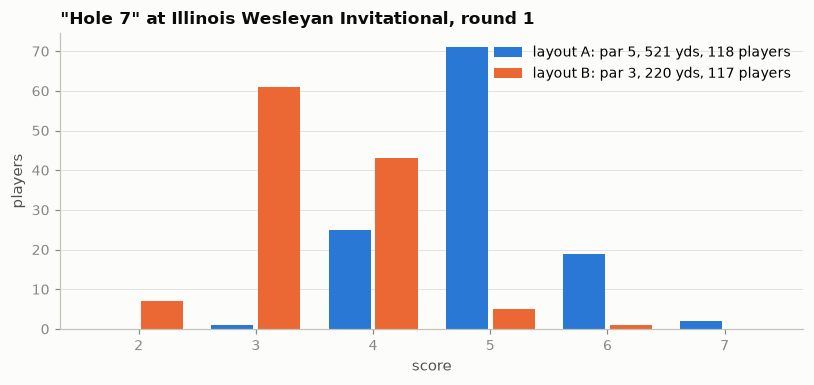

One field average over both groups would measure every player against a hole they did not play.
[PASS] every usable round has a layout and a field size


In [6]:
_, layout_id = np.unique(np.concatenate([P, Y], axis=1), axis=0, return_inverse=True)
rounds["layout_id"] = layout_id.astype(np.int64)

u = rounds[usable]
field_n = u.groupby(FIELD_KEYS).size().rename("field_players")
event_n = u.groupby(FIELD_KEYS[:2]).size().rename("event_players")
layouts_in_event = field_n.groupby(level=[0, 1]).size().rename("layouts_in_event")

rounds = rounds.join(field_n, on=FIELD_KEYS).join(event_n, on=FIELD_KEYS[:2]).join(layouts_in_event, on=FIELD_KEYS[:2])
fp = rounds["field_players"].fillna(0)

flag["orphan_layout"]   = usable & (fp < MIN_FIELD) & (rounds["event_players"] - fp >= MIN_FIELD)
flag["field_too_small"] = usable & (fp < MIN_FIELD) & ~flag["orphan_layout"]

multi = layouts_in_event[layouts_in_event > 1]
print(f"tournament-rounds with one layout : {(layouts_in_event == 1).sum():,}")
print(f"tournament-rounds with two+ layouts: {len(multi):,}   "
      f"({int(u.join(multi.rename('m'), on=FIELD_KEYS[:2])['m'].notna().sum()):,} rounds)")
print(f"orphan_layout  : {flag['orphan_layout'].sum():,} rounds")
print(f"field_too_small: {flag['field_too_small'].sum():,} rounds")

big = field_n[field_n >= 20].reset_index()
big = big[big.groupby(FIELD_KEYS[:2])["layout_id"].transform("size") == 2]
best = None
for (t, r), g in big.groupby(FIELD_KEYS[:2]):
    ia, ib = [rounds.index[usable & (rounds["tournament_id"] == t) & (rounds["round_number"] == r)
                           & (rounds["layout_id"] == l)].to_numpy() for l in g["layout_id"]]
    gap = np.abs(P[ia[0]] - P[ib[0]])
    if gap.max() >= 2 and (best is None or len(ia) + len(ib) > best[0]):
        best = (len(ia) + len(ib), t, r, int(gap.argmax()), ia, ib)

_, t, r, h, ia, ib = best
fig, ax = plt.subplots(figsize=(7.5, 3.6))
lo, hi = int(min(S[ia, h].min(), S[ib, h].min())), int(max(S[ia, h].max(), S[ib, h].max()))
xs = np.arange(lo, hi + 1)
for off, idx, col, name in [(-0.2, ia, BLUE, "A"), (0.2, ib, ORANGE, "B")]:
    cnt = pd.Series(S[idx, h]).value_counts().reindex(xs, fill_value=0)
    ax.bar(xs + off, cnt.values, width=0.36, color=col,
           label=f"layout {name}: par {P[idx[0], h]}, {Y[idx[0], h]} yds, {len(idx)} players")
ax.set_xticks(xs); ax.grid(axis="x", visible=False)
ax.set_title(f'"Hole {h + 1}" at {rounds.at[ia[0], "tournament_name"]}, round {r}')
ax.set_xlabel("score"); ax.set_ylabel("players"); ax.legend()
plt.tight_layout(); plt.show()
print("One field average over both groups would measure every player against a hole they did not play.")

check("every usable round has a layout and a field size", rounds.loc[usable, "field_players"].notna().all())

### 3b. Do the pars agree with the scores? (par response)

The paper's model uses par type as a covariate and defines birdie and bogey relative to par, so
the pars must be the pars of the holes that were actually played. Scores carry their own
evidence about par. Regress hole score on hole par within a field:

$$\text{score} = a + b \cdot \text{par}$$

On a correctly labelled course a hole one par longer costs close to one more stroke (`b` is
about 0.85 for men and 1.02 for women). When the pars belong to a different course, `b` falls
to about 0. If half the field was on another course, `b` lands near 0.4.

**The test uses an empirical null.** Genuine fields differ in `b` for two reasons: sampling
noise (fewer players, noisier `b`) and course design (a hard par 3 and an easy par 5 lower `b`
honestly). The second source is shared by every player in the field, so a standard error from
the hole-level regression alone understates it, by 2–3x in large fields. Instead, genuine
variation is measured directly from large fields (50+ players), where sampling noise is small:

* `typical` = median `b` of large fields, by gender,
* `tau` = between-course spread of `b`, from a robust SD (MAD) of large fields with their
  average sampling variance removed,
* for each field, $z = (b - \text{typical}) / \sqrt{\tau^2 + se^2}$.

A field is flagged when $z < -3.29$ (one-sided $p = 0.0005$). Across about 4,600 fields that
means about 2 genuine fields flagged by chance, a false-positive rate the notebook states and
checks rather than assumes.

A flagged field is then classified:

* `fabricated_field`: the field's cards are flat (average longest run of identical scores of 5
  or more; normal is about 3). The whole event was entered as round totals spread across holes.
  This rule also applies on its own, without a par-response flag.
* **mixed-course field**: some schools track the pars and some do not. See 3c.
* `wrong_pars`: real-looking scores, wrong pars, no school can be rescued. The scores may be
  real, but `par`, `to_par` and `yardage` describe a different course, so birdie and bogey
  cannot be defined.

genuine par response (fields of 50+ players):
             typical    tau  reference_fields
team_gender                                  
Men            0.849  0.079               830
Women          1.018  0.094               365

fields tested: 4,600   flagged by the par test: 48  (2,028 rounds)   fabricated: 13 (6 of them pass the par test)


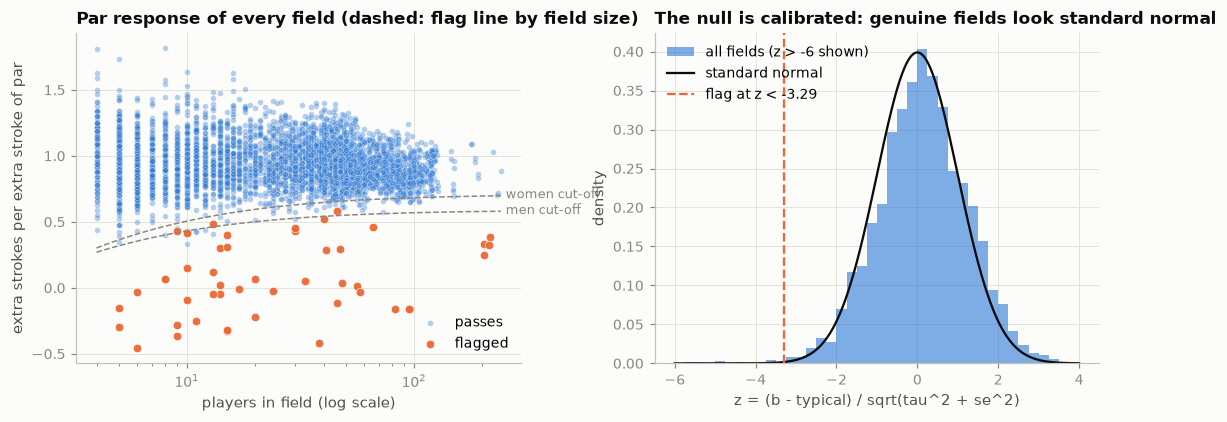


flagged or fabricated fields:
                               tournament_name  round_number team_gender  players  par_response      z  mean_longest_run  fabricated
                          Wartburg Fall Invite             1       Women       96         -0.16 -11.56              2.70       False
                          Wartburg Fall Invite             2       Women       95         -0.16 -11.53              2.99       False
                            Conquer The Island             1         Men       82         -0.16 -11.51              2.87       False
         Westminster Women's Fall Invitational             1       Women       38         -0.41 -10.75              2.63       False
              Landmark Conference Fall Preview             2         Men       46         -0.12 -10.41              2.70       False
                Final 36 hole Qualifying - UAA             1       Women        9         -0.36  -9.59              2.56       False
                     NCCAA Regional To

In [7]:
def par_response(idx_groups):
    "OLS slope of score on par (and its sampling standard error) for each group of round positions."
    out = []
    for key, idx in idx_groups:
        x, y = P[idx].ravel().astype(float), S[idx].ravel().astype(float)
        sxx = ((x - x.mean()) ** 2).sum()
        b = ((x - x.mean()) * (y - y.mean())).sum() / sxx
        resid = y - y.mean() - b * (x - x.mean())
        se = np.sqrt((resid ** 2).sum() / (len(x) - 2) / sxx)
        out.append((key, len(idx), b, se))
    return pd.DataFrame(out, columns=["key", "players", "par_response", "se"])

def mad_sd(s):
    return 1.4826 * np.median(np.abs(s - np.median(s)))

testable = usable & (fp >= MIN_FIELD).to_numpy()
pos = pd.Series(np.flatnonzero(testable), index=pd.MultiIndex.from_frame(rounds.loc[testable, FIELD_KEYS]))
groups = [(k, v.to_numpy()) for k, v in pos.groupby(level=[0, 1, 2])]

fields = par_response(groups)
fields[FIELD_KEYS] = pd.DataFrame(fields["key"].tolist(), index=fields.index)
fields["mean_longest_run"] = [run_len[idx].mean() for _, idx in groups]
first = [idx[0] for _, idx in groups]
fields["tournament_name"] = rounds["tournament_name"].to_numpy()[first]
fields["team_gender"] = rounds["team_gender"].to_numpy()[first]

ref = fields[fields["players"] >= PAR_RESPONSE_REF_MIN]
NULL = pd.DataFrame({
    "typical": ref.groupby("team_gender")["par_response"].median(),
    "tau": ref.groupby("team_gender").apply(
        lambda g: np.sqrt(max(mad_sd(g["par_response"]) ** 2 - np.median(g["se"] ** 2), 0)), include_groups=False),
    "reference_fields": ref.groupby("team_gender").size(),
})
print("genuine par response (fields of 50+ players):")
print(NULL.round(3).to_string())

def par_z(df):
    "z-score of each field's par response against genuine fields of its gender."
    nl = NULL.loc[df["team_gender"]].to_numpy()
    return (df["par_response"].to_numpy() - nl[:, 0]) / np.sqrt(nl[:, 1] ** 2 + df["se"].to_numpy() ** 2)

fields["z"] = par_z(fields)
fields["fails"] = fields["z"] < -PAR_RESPONSE_Z
fields["fabricated"] = fields["mean_longest_run"] >= FABRICATED_MEAN_RUN

print(f"\nfields tested: {len(fields):,}   flagged by the par test: {fields['fails'].sum()}  "
      f"({fields.loc[fields['fails'], 'players'].sum():,} rounds)   fabricated: {fields['fabricated'].sum()} "
      f"({(fields['fabricated'] & ~fields['fails']).sum()} of them pass the par test)")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), gridspec_kw={"wspace": 0.3})
ax = axes[0]
for mask, col, lab in [(~fields["fails"], BLUE, "passes"), (fields["fails"], ORANGE, "flagged")]:
    ax.scatter(fields.loc[mask, "players"], fields.loc[mask, "par_response"], s=14 if col == BLUE else 30,
               color=col, alpha=0.35 if col == BLUE else 0.95, edgecolor=SURFACE, linewidth=0.4, label=lab)
ns = np.geomspace(4, fields["players"].max(), 60)
for g_, row in NULL.iterrows():
    se_n = np.median(fields.loc[fields["team_gender"] == g_, "se"] * np.sqrt(fields.loc[fields["team_gender"] == g_, "players"]))
    ax.plot(ns, row["typical"] - PAR_RESPONSE_Z * np.sqrt(row["tau"] ** 2 + (se_n / np.sqrt(ns)) ** 2),
            color=MUTED, lw=1, ls="--")
    ax.text(ns[-1] * 1.05, row["typical"] - PAR_RESPONSE_Z * row["tau"], f"{g_.lower()} cut-off",
            va="center", fontsize=8.5, color=MUTED)
ax.set_xscale("log"); ax.set_title("Par response of every field (dashed: flag line by field size)")
ax.set_xlabel("players in field (log scale)"); ax.set_ylabel("extra strokes per extra stroke of par")
ax.legend(loc="lower right")

ax = axes[1]
zz = fields.loc[fields["z"] > -6, "z"]
ax.hist(zz, bins=np.arange(-6, 4.01, 0.25), density=True, color=BLUE, alpha=0.6, label="all fields (z > -6 shown)")
xg = np.linspace(-6, 4, 200)
ax.plot(xg, norm.pdf(xg), color=INK, lw=1.5, label="standard normal")
ax.axvline(-PAR_RESPONSE_Z, color=ORANGE, lw=1.5, ls="--", label=f"flag at z < -{PAR_RESPONSE_Z}")
ax.set_title("The null is calibrated: genuine fields look standard normal")
ax.set_xlabel("z = (b - typical) / sqrt(tau^2 + se^2)"); ax.set_ylabel("density"); ax.legend(loc="upper left")
plt.show()

print("\nflagged or fabricated fields:")
print(fields[fields["fails"] | fields["fabricated"]].sort_values("z")
      [["tournament_name", "round_number", "team_gender", "players", "par_response", "z", "mean_longest_run", "fabricated"]]
      .round(2).to_string(index=False))

core = fields.loc[fields["z"].between(-3, 3), "z"]
check("the null is calibrated: central z-scores have SD close to 1 (0.85-1.20)",
      0.85 <= core.std() <= 1.20, f"SD {core.std():.2f}")
tail = (fields["z"] < -2).mean()
check("the lower tail is not much heavier than normal at z < -2 (under 2x the normal 2.3%), so the cut-off is not trimming ordinary golf",
      tail < 2 * norm.cdf(-2), f"{tail:.2%}")
check("the par test flags under 3% of fields", fields["fails"].mean() < 0.03, f"{fields['fails'].mean():.2%}")

**Note on small fabricated fields.** A few small fields (4–6 players) are flagged
`fabricated_field` while their par response is normal. Resampling genuine cards into random
4-player fields puts the field average longest run at 5 or more about 0.4% of the time, so
one or two of these may be chance. They are kept as drops, because flat cards create artificial
streaks, and they are listed above so they can be checked by hand.

### 3c. Rescuing the half of a mixed-course field that has the right pars

In a few large events two courses were used but **one** par set was attached to everyone. The
field as a whole fails 3b, yet half of it is labelled correctly. Teams play a course together,
so the split is by school.

For each school in a flagged (non-fabricated) field: average its players' scores hole by hole
and correlate those 18 hole means with the 18 pars. A school on the labelled course lands around
0.8; a school on the other course lands around 0.

* schools at or above `0.55` are **kept**,
* everyone else in that field is dropped as `wrong_course_labels` (including schools with fewer
  than 4 players, who cannot be judged),
* the rescue only stands if the schools form **two clearly separated clusters** (a gap of at
  least 0.30), the kept group has at least 10 players, **and** the kept group passes the
  par-response test on its own. Otherwise the whole field is `wrong_pars`.

fabricated_field   : 128 rounds
wrong_pars         : 1,094 rounds
wrong_course_labels: 414 rounds dropped; 424 rescued in 4 fields


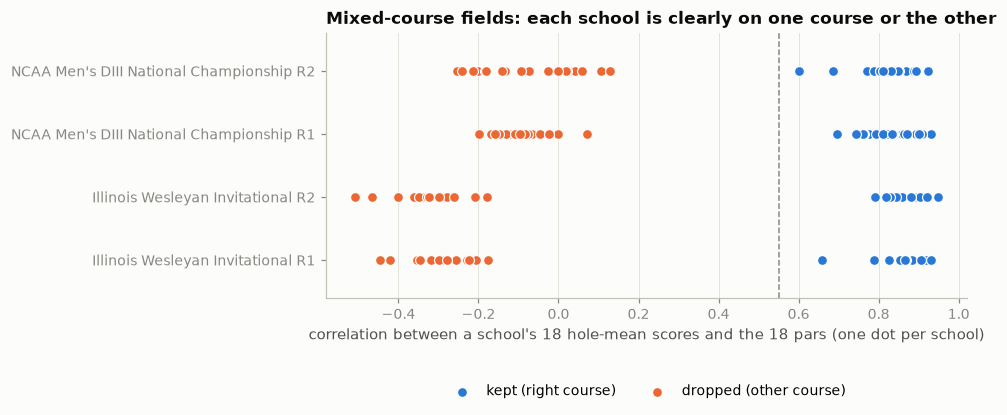

[PASS] in rescued fields no school sits near the cut-off (clean two-cluster split)  (highest dropped 0.13, lowest kept 0.60)
[PASS] every rescued half-field passes the par-response test on its own  (par response 0.79 to 0.89)


In [8]:
school = rounds["school_id"].to_numpy()
flag["fabricated_field"] = False
flag["wrong_pars"] = False
flag["wrong_course_labels"] = False
salvage_rows = []

for (key, idx), (_, f) in zip(groups, fields.iterrows()):
    if f["fabricated"]:
        flag.loc[idx, "fabricated_field"] = True
        continue
    if not f["fails"]:
        continue
    keep = np.zeros(len(idx), dtype=bool)
    rows_here = []
    for s in np.unique(school[idx]):
        m = school[idx] == s
        corr = np.nan
        if m.sum() >= SALVAGE_SCHOOL_MIN_PLAYERS:
            corr = np.corrcoef(S[idx[m]].mean(axis=0), P[idx[0]])[0, 1]
            keep |= m & (corr >= SALVAGE_SCHOOL_MIN_CORR)
        rows_here.append({"key": key, "tournament_name": f["tournament_name"], "round_number": key[1],
                          "school_id": s, "players": int(m.sum()), "school_par_corr": corr})
    corrs = pd.Series([r_["school_par_corr"] for r_ in rows_here]).dropna()
    lo_side, hi_side = corrs[corrs < SALVAGE_SCHOOL_MIN_CORR], corrs[corrs >= SALVAGE_SCHOOL_MIN_CORR]
    two_clusters = len(lo_side) > 0 and len(hi_side) > 0 and hi_side.min() - lo_side.max() >= SALVAGE_MIN_SEPARATION
    rescued = False
    if two_clusters and keep.sum() >= SALVAGE_MIN_KEPT:
        re_ = par_response([(key, idx[keep])]).assign(team_gender=f["team_gender"])
        rescued = bool(par_z(re_)[0] >= -PAR_RESPONSE_Z)
    if rescued:
        flag.loc[idx[~keep], "wrong_course_labels"] = True
    else:
        flag.loc[idx, "wrong_pars"] = True
    salvage_rows += [dict(r_, field_rescued=rescued) for r_ in rows_here]

sal = pd.DataFrame(salvage_rows)
rescued_keys = sal.loc[sal["field_rescued"], "key"].drop_duplicates().tolist()
print(f"fabricated_field   : {flag['fabricated_field'].sum():,} rounds")
print(f"wrong_pars         : {flag['wrong_pars'].sum():,} rounds")
print(f"wrong_course_labels: {flag['wrong_course_labels'].sum():,} rounds dropped; "
      f"{sum(len(i) for k, i in groups if k in rescued_keys) - flag['wrong_course_labels'].sum():,} rescued "
      f"in {len(rescued_keys)} fields")

fig, ax = plt.subplots(figsize=(9, 0.62 * len(rescued_keys) + 1.6))
labels = []
for row_i, key in enumerate(rescued_keys):
    g = sal[(sal["key"] == key) & sal["school_par_corr"].notna()]
    kept_s = g["school_par_corr"] >= SALVAGE_SCHOOL_MIN_CORR
    ax.scatter(g.loc[kept_s, "school_par_corr"], np.full(kept_s.sum(), row_i), s=42, color=BLUE,
               edgecolor=SURFACE, linewidth=0.8, label="kept (right course)" if row_i == 0 else None)
    ax.scatter(g.loc[~kept_s, "school_par_corr"], np.full((~kept_s).sum(), row_i), s=42, color=ORANGE,
               edgecolor=SURFACE, linewidth=0.8, label="dropped (other course)" if row_i == 0 else None)
    labels.append(f"{g['tournament_name'].iloc[0][:44]} R{key[1]}")
ax.axvline(SALVAGE_SCHOOL_MIN_CORR, color=MUTED, lw=1, ls="--")
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels); ax.set_ylim(-0.6, len(labels) - 0.4)
ax.set_xlabel("correlation between a school's 18 hole-mean scores and the 18 pars (one dot per school)")
ax.set_title("Mixed-course fields: each school is clearly on one course or the other")
ax.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.28)); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

judged = sal[sal["field_rescued"] & sal["school_par_corr"].notna()]
gap_lo = judged.loc[judged["school_par_corr"] < SALVAGE_SCHOOL_MIN_CORR, "school_par_corr"].max()
gap_hi = judged.loc[judged["school_par_corr"] >= SALVAGE_SCHOOL_MIN_CORR, "school_par_corr"].min()
check("in rescued fields no school sits near the cut-off (clean two-cluster split)",
      gap_hi - gap_lo >= SALVAGE_MIN_SEPARATION, f"highest dropped {gap_lo:.2f}, lowest kept {gap_hi:.2f}")
resc = par_response([(k, i[~flag.loc[i, "wrong_course_labels"].to_numpy()]) for k, i in groups if k in rescued_keys])
resc["team_gender"] = [rounds.at[i[0], "team_gender"] for k, i in groups if k in rescued_keys]
check("every rescued half-field passes the par-response test on its own",
      (par_z(resc) >= -PAR_RESPONSE_Z).all(), f"par response {resc['par_response'].min():.2f} to {resc['par_response'].max():.2f}")

## 4. Duplicate checks

Two complete 18-hole cards matching hole for hole does not happen by chance (the cell below
estimates the odds). Duplicates matter twice over for this study: they double-count a player's
sequence of holes, and a duplicated event creates a second, partial field whose hole averages
are computed from the wrong set of players.

| reason | rule | action |
|---|---|---|
| `repeat_of_own_round` | a player's card is identical to one of their earlier rounds in the same tournament | the later round is dropped |
| `duplicate_event_entry` | a player's card appears in two different tournaments that start on the same date | one event entered under two ids (for example a tri-match recorded as two duals); the copy under the later id is dropped |
| `copied_card` | a player's card appears in tournaments on different dates | a card copied into another event; there is no way to tell which is real, so every copy is dropped |
| `twin_card` | two different players in the same tournament-round have identical cards | both are dropped, because there is no way to tell whose card it is |

In [9]:
card_bytes = pd.Series([row.tobytes() for row in S.astype(np.int16)], index=rounds.index)
c = (rounds.loc[card_ok, ["tournament_id", "round_number", "player_id", "tournament_start_date"]]
     .assign(card=card_bytes[card_ok])
     .sort_values(["player_id", "tournament_start_date", "tournament_id", "round_number"]))

n_dates = c.groupby(["player_id", "card"])["tournament_start_date"].transform("nunique")
copied = n_dates > 1
repeat = c.duplicated(["tournament_id", "player_id", "card"], keep="first") & ~copied
dup_event = c.duplicated(["player_id", "card", "tournament_start_date"], keep="first") & ~repeat & ~copied
twin = c.duplicated(["tournament_id", "round_number", "card"], keep=False)

for name, m in [("repeat_of_own_round", repeat), ("duplicate_event_entry", dup_event),
                ("copied_card", copied), ("twin_card", twin)]:
    flag[name] = False
    flag.loc[m.index[m], name] = True
DUP_REASONS = ["repeat_of_own_round", "duplicate_event_entry", "copied_card", "twin_card"]

# chance of two independent cards matching: product over holes of P(two players score the same)
tp = (S - P)[card_ok]
p_same_hole = (pd.Series(tp.ravel()).value_counts(normalize=True) ** 2).sum()
p_same_card = p_same_hole ** N_HOLES
pairs_within_round = (c.groupby(["tournament_id", "round_number"]).size().pipe(lambda n: n * (n - 1) / 2)).sum()

survivors = ~flag.drop(columns=DUP_REASONS).any(axis=1)
print(f"P(two players match on one hole) = {p_same_hole:.3f}  ->  P(match on all 18) = {p_same_card:.1e}")
print(f"twin cards: expected by chance {pairs_within_round * p_same_card:.2f} pairs, observed {flag['twin_card'].sum():,} rounds")
for name in DUP_REASONS:
    print(f"{name:22s}: {flag[name].sum():4d} rounds ({(flag[name] & survivors).sum():,} not already dropped for another reason)")

ev_pairs = (rounds.loc[flag["duplicate_event_entry"]].assign(card=card_bytes)
            .merge(c[["player_id", "card", "tournament_id"]], on=["player_id", "card"], suffixes=("", "_orig"))
            .query("tournament_id != tournament_id_orig"))
ev_pairs["original_event"] = rounds.drop_duplicates("tournament_id").set_index("tournament_id").loc[
    ev_pairs["tournament_id_orig"], "tournament_name"].to_numpy()
print("\nduplicate_event_entry: the same event under two ids")
print(ev_pairs.groupby(["original_event", "tournament_name"]).size().sort_values(ascending=False).head(8).to_string())
show_cards(rounds.index[flag["twin_card"] & survivors], "twin_card examples (consecutive lines are different players):", 4)

check("identical cards are far more common than chance allows (so they are entry errors)",
      flag["twin_card"].sum() > 20 * max(pairs_within_round * p_same_card, 0.5))

## 5. One status per round

A round can trip several checks. It gets the **first** reason in the order below, which runs
from "nothing was played" to "everything looks fine except it is a copy". A final pass re-checks
the field rules, because removing rounds can leave a field too small or mostly flat.

after other drops: 0 more rounds marked fabricated_field, 5 more marked field_too_small

segment                Men Qualifying  Men Tournament  Women Qualifying  Women Tournament     all  pct_of_raw
status                                                                                                       
kept                             1864          102785               634             59890  165173      97.972
no_card                             0              79                 0               101     180       0.107
nine_hole_round                    98             314                75               336     823       0.488
incomplete_card                    14               4                 1                55      74       0.044
invalid_par                         0              15                 0                13      28       0.017
placeholder_card                    3              22                 2                13      40       0.024
impossible_score               

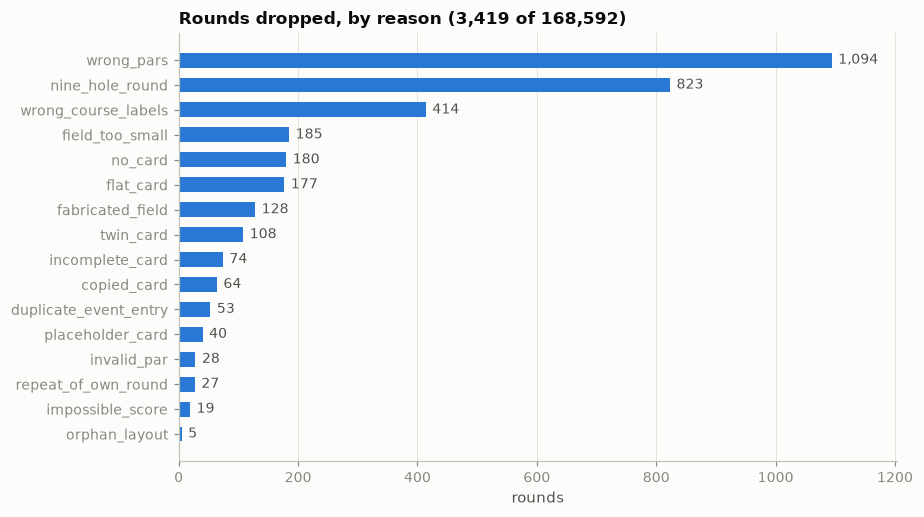

[PASS] every round has exactly one status
[PASS] a kept round trips no check at all


[PASS] the drop reasons are all ones this notebook defines


In [10]:
PRIORITY = ["no_card", "nine_hole_round", "incomplete_card", "invalid_par", "placeholder_card",
            "impossible_score", "flat_card", "orphan_layout", "field_too_small", "fabricated_field",
            "wrong_pars", "wrong_course_labels"] + DUP_REASONS
assert set(PRIORITY) == set(flag.columns)

rounds["status"] = np.select([flag[r].to_numpy() for r in PRIORITY], PRIORITY, default="kept")

k_ = rounds[rounds["status"] == "kept"]
still_flat = k_.groupby(FIELD_KEYS)["longest_run"].transform("mean") >= FABRICATED_MEAN_RUN
rounds.loc[still_flat.index[still_flat], "status"] = "fabricated_field"
left = rounds[rounds["status"] == "kept"].groupby(FIELD_KEYS)["player_id"].transform("size")
shrunk = left.index[left < MIN_FIELD]
rounds.loc[shrunk, "status"] = "field_too_small"
print(f"after other drops: {int(still_flat.sum())} more rounds marked fabricated_field, "
      f"{len(shrunk)} more marked field_too_small")

kept = (rounds["status"] == "kept").to_numpy()
rounds["field_size"] = rounds[kept].groupby(FIELD_KEYS)["player_id"].transform("size")

summary = (rounds.groupby(["status", "segment"]).size().unstack(fill_value=0)
           .reindex(["kept"] + PRIORITY).fillna(0).astype(int))
summary["all"] = summary.sum(axis=1)
summary["pct_of_raw"] = (summary["all"] / n_raw_rounds * 100).round(3)
print()
print(summary.to_string())
print(f"\nkept {kept.sum():,} of {n_raw_rounds:,} rounds ({kept.mean():.2%});  dropped {(~kept).sum():,}")

drops = summary.drop(index="kept")["all"].sort_values()
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.barh(drops.index, drops.values, color=BLUE, height=0.6)
for y, v in zip(drops.index, drops.values):
    ax.text(v + drops.max() * 0.01, y, f"{v:,}", va="center", fontsize=9, color="#52514e")
ax.set_xlim(0, drops.max() * 1.1); ax.grid(axis="y", visible=False)
ax.set_title(f"Rounds dropped, by reason ({(~kept).sum():,} of {n_raw_rounds:,})"); ax.set_xlabel("rounds")
plt.tight_layout(); plt.show()

check("every round has exactly one status", rounds["status"].notna().all() and len(rounds) == n_raw_rounds)
check("a kept round trips no check at all", not flag[kept].any(axis=1).any())
check("the drop reasons are all ones this notebook defines", set(rounds["status"]) <= set(PRIORITY) | {"kept"})

## 6. Build the clean tables

Rounds are selected whole, so the hole table is 18 rows per round by construction. Value-level
repairs on kept rows (the row stays):

* `yardage` outside a plausible range for its par becomes missing.
* `round_date`: when a tournament's earliest round date is exactly one day before its start
  date, every round date in that tournament is shifted forward one day. This is a systematic
  off-by-one (it accounts for almost all out-of-range dates). Dates still outside the
  tournament window after that become missing. `round_date` is absent for about half the file
  anyway; chronological order should use `tournament_start_date` and `round_number`.
* `course_name` is dropped (it is empty in every row).

Columns added:

| column | meaning |
|---|---|
| `round_id` | one player's round; replaces the three-column key |
| `layout_id`, `field_size` | the field (same holes, same day) and how many clean rounds it holds |
| `season_id`, `season_label` | the August–May academic season |
| `is_extreme_round` | median hole is +5 or worse: real golf by true beginners, kept and labelled |
| `is_match_name` | the event name suggests a dual, tri, quad or match. The paper excluded match play because the format changes how holes are played. The scoring format is not recorded here, so these events are labelled, not dropped |

In [11]:
keep_rows = np.repeat(kept, N_HOLES)
holes = raw.loc[keep_rows].drop(columns=["course_name"]).reset_index(drop=True)
r_kept = rounds[kept].reset_index(drop=True)

def rep(col):
    return np.repeat(r_kept[col].to_numpy(), N_HOLES)

holes["round_id"] = np.repeat((r_kept["tournament_id"].astype(str) + "-" + r_kept["round_number"].astype(str)
                               + "-" + r_kept["player_id"].astype(str)).to_numpy(), N_HOLES)
holes["layout_id"]  = rep("layout_id")
holes["field_size"] = rep("field_size").astype(np.int32)
extreme = np.median((S - P)[kept], axis=1) >= EXTREME_ROUND_MEDIAN_TO_PAR
holes["is_extreme_round"] = np.repeat(extreme, N_HOLES)
holes["is_match_name"] = holes["tournament_name"].str.contains(MATCH_NAME_PATTERN, case=False, regex=True)

# ---- dates and season ----
for col in ["tournament_start_date", "tournament_end_date", "round_date"]:
    holes[col] = pd.to_datetime(holes[col], errors="coerce")
first_date = holes.groupby("tournament_id")["round_date"].transform("min")
shifted = first_date == holes["tournament_start_date"] - pd.Timedelta(days=1)
holes.loc[shifted, "round_date"] += pd.Timedelta(days=1)
bad_date = holes["round_date"].notna() & ~holes["round_date"].between(holes["tournament_start_date"], holes["tournament_end_date"])
holes.loc[bad_date, "round_date"] = pd.NaT
start = holes["tournament_start_date"]
holes["season_id"] = start.dt.year.where(start.dt.month >= 8, start.dt.year - 1).astype(np.int16)
holes["season_label"] = holes["season_id"].astype(str) + "-" + ((holes["season_id"] + 1) % 100).astype(str).str.zfill(2)

# ---- yardage ----
holes["yardage"] = holes["yardage"].astype("float64")
bad_yards = pd.Series(False, index=holes.index)
for par, (lo, hi) in YARDAGE_BOUNDS.items():
    bad_yards |= (holes["par"] == par) & ~holes["yardage"].between(lo, hi)
holes.loc[bad_yards, "yardage"] = np.nan

# ---- types and order ----
for col in ["hole_number", "par", "score", "to_par", "round_number"]:
    holes[col] = holes[col].astype(np.int16)
for col in ["tournament_level", "team_gender", "season_label"]:
    holes[col] = holes[col].astype("category")
ROUND_META = ["round_id", "tournament_id", "tournament_name", "tournament_level", "tournament_start_date",
              "tournament_end_date", "round_date", "season_id", "season_label", "round_number", "team_gender",
              "school_id", "school_name", "player_id", "player_name", "course_id", "layout_id", "field_size",
              "is_extreme_round", "is_match_name"]
holes = holes[ROUND_META[:-2] + ["hole_number", "par", "yardage", "score", "to_par"] + ROUND_META[-2:]]

# ---- one row per round ----
clean_rounds = holes.iloc[::N_HOLES][ROUND_META].reset_index(drop=True)
Sk, Pk = S[kept], P[kept]
clean_rounds["round_score"]  = Sk.sum(axis=1)
clean_rounds["round_par"]    = Pk.sum(axis=1)
clean_rounds["round_to_par"] = clean_rounds["round_score"] - clean_rounds["round_par"]
clean_rounds["front_nine"]   = Sk[:, :9].sum(axis=1)
clean_rounds["back_nine"]    = Sk[:, 9:].sum(axis=1)
clean_rounds["birdies_or_better"] = (Sk < Pk).sum(axis=1)
clean_rounds["pars"]              = (Sk == Pk).sum(axis=1)
clean_rounds["bogeys"]            = (Sk == Pk + 1).sum(axis=1)
clean_rounds["doubles_or_worse"]  = (Sk >= Pk + 2).sum(axis=1)

print(f"clean holes : {len(holes):,} rows x {holes.shape[1]} columns")
print(f"clean rounds: {len(clean_rounds):,} rows x {clean_rounds.shape[1]} columns")
print(f"yardage blanked: {int(bad_yards.sum()):,} holes")
print(f"round_date: shifted +1 day in {int(shifted.sum() / N_HOLES):,} rounds, blanked in {int(bad_date.sum() / N_HOLES):,} rounds")
print(f"is_extreme_round: {int(extreme.sum())} rounds   is_match_name: {int(clean_rounds['is_match_name'].sum()):,} rounds "
      f"in {clean_rounds.loc[clean_rounds['is_match_name'], 'tournament_id'].nunique()} events")
holes.head(3)

## 7. Final test suite on the clean tables

These tests run against the finished tables, independently of how they were built. They are
the contract the analysis notebook relies on.

In [12]:
print("--- shape and keys ---")
per_round = holes.groupby("round_id", sort=False)["hole_number"]
check("every round has exactly 18 rows", (per_round.size() == N_HOLES).all(), f"{holes['round_id'].nunique():,} rounds")
check("every round is holes 1..18, each once, in order",
      (holes["hole_number"].to_numpy().reshape(-1, N_HOLES) == np.arange(1, N_HOLES + 1)).all())
check("(round_id, hole_number) is unique", not holes.duplicated(["round_id", "hole_number"]).any())
check("round_id matches (tournament_id, round_number, player_id) one to one",
      clean_rounds["round_id"].is_unique and not clean_rounds.duplicated(ROUND_KEYS).any())
check("rounds table and holes table describe the same rounds",
      len(clean_rounds) * N_HOLES == len(holes) and set(clean_rounds["round_id"]) == set(holes["round_id"]))

print("\n--- values ---")
check("no missing score, par, to_par or key", holes[["score", "par", "to_par", "tournament_id", "player_id",
      "school_id", "layout_id", "team_gender", "tournament_level", "season_id"]].notna().all().all())
check("par is 3, 4, 5 or 6", holes["par"].isin(VALID_PARS).all())
check("par 6 only on holes of 550+ yards", (holes.loc[holes["par"] == 6, "yardage"] >= PAR6_MIN_YARDS).all(),
      f"{(holes['par'] == 6).sum()} par-6 holes")
check("1 <= score <= par + 15 on every hole", (holes["score"].between(1, holes["par"] + MAX_OVER_PAR)).all(),
      f"max over par {int(holes['to_par'].max())}")
check("to_par == score - par", (holes["score"] - holes["par"] == holes["to_par"]).all())
check("no hole-in-one on a par 4 or longer", not ((holes["score"] == 1) & (holes["par"] >= 4)).any())
check("no round has two holes-in-one", (holes["score"] == 1).groupby(holes["round_id"], sort=False).sum().max() <= 1)
check("round par is a real course par (64 to 76)", clean_rounds["round_par"].between(64, 76).all(),
      f"range {clean_rounds['round_par'].min()}-{clean_rounds['round_par'].max()}")
check("every remaining yardage is plausible for its par",
      all(holes.loc[(holes["par"] == p) & holes["yardage"].notna(), "yardage"].between(lo, hi).all()
          for p, (lo, hi) in YARDAGE_BOUNDS.items()))
check("every remaining round_date is inside its tournament",
      holes.loc[holes["round_date"].notna()].eval("tournament_start_date <= round_date <= tournament_end_date").all())
check("no tournament starts in June or July (season split is unambiguous)",
      not holes["tournament_start_date"].dt.month.isin([6, 7]).any())

print("\n--- fields ---")
hole_field = holes.groupby(FIELD_KEYS + ["hole_number"], sort=False)
check("one par per hole within a field (no two courses under one hole number)", (hole_field["par"].nunique() == 1).all())
check("one yardage per hole within a field", (hole_field["yardage"].nunique(dropna=False) == 1).all())
check(f"every field has at least {MIN_FIELD} players and field_size is correct",
      (clean_rounds["field_size"] >= MIN_FIELD).all()
      and (clean_rounds.groupby(FIELD_KEYS)["round_id"].transform("size") == clean_rounds["field_size"]).all())
check("no tournament mixes genders", (clean_rounds.groupby("tournament_id")["team_gender"].nunique() == 1).all())

kpos = np.flatnonzero(kept)
gpos = pd.Series(kpos, index=pd.MultiIndex.from_frame(rounds.loc[kept, FIELD_KEYS]))
final_groups = [(k, v.to_numpy()) for k, v in gpos.groupby(level=[0, 1, 2])]
final_fields = par_response(final_groups)
final_fields["team_gender"] = [rounds.at[i[0], "team_gender"] for _, i in final_groups]
final_fields["z"] = par_z(final_fields)
check("every field passes the par-response test", (final_fields["z"] >= -PAR_RESPONSE_Z).all(),
      f"{len(final_fields):,} fields, lowest z {final_fields['z'].min():.2f}")
check("no fabricated field remains (field-average longest run under 5)",
      max(run_len[i].mean() for _, i in final_groups) < FABRICATED_MEAN_RUN)

print("\n--- cards ---")
check("no flat card remains", not is_flat[kept].any())
kc = rounds.loc[kept, ROUND_KEYS].assign(card=card_bytes[kept])
check("no two players in a tournament-round share a card", not kc.duplicated(["tournament_id", "round_number", "card"], keep=False).any())
check("no player has the same card twice anywhere in the data (within or across events)",
      not kc.duplicated(["player_id", "card"], keep=False).any())

print("\n--- plausibility ---")
for g, grp in holes[holes["par"] == 3].groupby("team_gender", observed=True):
    one_in = len(grp) / max((grp["score"] == 1).sum(), 1)
    check(f"hole-in-one rate on par 3s is believable ({g})", 1500 <= one_in <= 30000, f"1 in {one_in:,.0f}")
pr = final_fields[final_fields["players"] >= 20].groupby("team_gender")["par_response"].median()
check("median par response is near 1 stroke per stroke of par", pr.between(0.75, 1.15).all(),
      ", ".join(f"{k} {v:.2f}" for k, v in pr.items()))

--- shape and keys ---
[PASS] every round has exactly 18 rows  (165,173 rounds)
[PASS] every round is holes 1..18, each once, in order
[PASS] (round_id, hole_number) is unique
[PASS] round_id matches (tournament_id, round_number, player_id) one to one


[PASS] rounds table and holes table describe the same rounds

--- values ---
[PASS] no missing score, par, to_par or key
[PASS] par is 3, 4, 5 or 6
[PASS] par 6 only on holes of 550+ yards  (61 par-6 holes)
[PASS] 1 <= score <= par + 15 on every hole  (max over par 15)
[PASS] to_par == score - par
[PASS] no hole-in-one on a par 4 or longer
[PASS] no round has two holes-in-one
[PASS] round par is a real course par (64 to 76)  (range 65-74)
[PASS] every remaining yardage is plausible for its par
[PASS] every remaining round_date is inside its tournament


[PASS] no tournament starts in June or July (season split is unambiguous)

--- fields ---
[PASS] one par per hole within a field (no two courses under one hole number)
[PASS] one yardage per hole within a field
[PASS] every field has at least 4 players and field_size is correct
[PASS] no tournament mixes genders


[PASS] every field passes the par-response test  (4,545 fields, lowest z -3.24)
[PASS] no fabricated field remains (field-average longest run under 5)

--- cards ---
[PASS] no flat card remains
[PASS] no two players in a tournament-round share a card
[PASS] no player has the same card twice anywhere in the data (within or across events)

--- plausibility ---
[PASS] hole-in-one rate on par 3s is believable (Men)  (1 in 4,567)
[PASS] hole-in-one rate on par 3s is believable (Women)  (1 in 5,714)
[PASS] median par response is near 1 stroke per stroke of par  (Men 0.85, Women 1.04)


## 8. Did cleaning remove bad data without moving the real signal?

Most of the complete cards that were dropped hold **real scores with the wrong labels**, so
removing them should barely move the scoring distribution. The numbers that **should** move are
the ones bad data inflates: eagles (a 3 on a hole wrongly labelled par 5) and holes-in-one
(placeholder 1s). The two quantities this study is built on, the chance of a birdie-or-better
after a birdie-or-better and of a bogey-or-worse after a bogey-or-worse, are printed as well:
cleaning should leave them essentially where they were, so that whatever the analysis finds
was not created or removed by the cleaning.

                    Men Tournament             Women Tournament           
                      raw complete       clean     raw complete      clean
rounds                  104056.000  102785.000        60819.000  59890.000
mean round to par            7.950       7.933           17.685     17.606
median round to par          7.000       7.000           15.000     15.000
eagle or better %            0.311       0.264            0.106      0.072
birdie %                     9.995       9.941            4.725      4.668
par %                       49.149      49.330           34.191     34.360
bogey %                     29.889      29.895           35.007     35.109
double or worse %           10.656      10.571           25.972     25.790
P(BoB | prev BoB) %         11.327      11.252            7.838      7.696
P(BoW | prev BoW) %         45.939      45.959           68.005     68.027
par-3 holes per ace       2858.033    4486.632         3509.875   5924.310


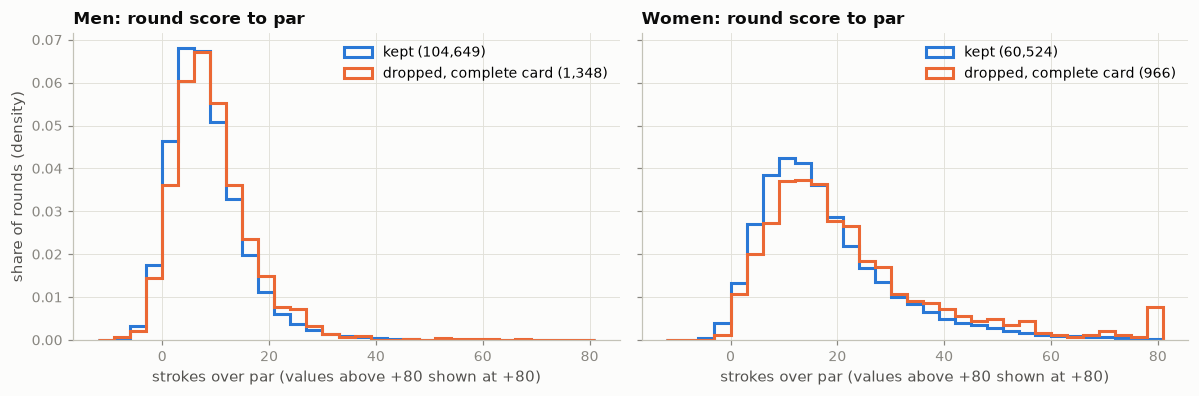

[PASS] mean round score moved by less than 0.15 strokes (Men Tournament)  (0.017)
[PASS] birdie, par, bogey and double rates each moved by less than 0.5 percentage points (Men Tournament)  (largest move 0.18 pp)
[PASS] the artifacts shrink: fewer eagles and fewer holes-in-one after cleaning (Men Tournament)  (eagles 0.311% -> 0.264%, one ace per 2,858 -> 4,487 par 3s)
[PASS] cleaning leaves the back-to-back rates the study measures essentially unchanged (Men Tournament)  (largest move 0.08 pp)
[PASS] mean round score moved by less than 0.15 strokes (Women Tournament)  (0.079)
[PASS] birdie, par, bogey and double rates each moved by less than 0.5 percentage points (Women Tournament)  (largest move 0.18 pp)
[PASS] the artifacts shrink: fewer eagles and fewer holes-in-one after cleaning (Women Tournament)  (eagles 0.106% -> 0.072%, one ace per 3,510 -> 5,924 par 3s)
[PASS] cleaning leaves the back-to-back rates the study measures essentially unchanged (Women Tournament)  (largest move 0.1

In [13]:
seg_order = ["Men Tournament", "Women Tournament"]
complete = (unscored == 0) & par_ok.all(axis=1)
rtp = (S - P).sum(axis=1)

def headline(mask):
    tp = (S - P)[mask]
    bob, bow = tp <= -1, tp >= 1
    out = {"rounds": int(mask.sum()), "mean round to par": rtp[mask].mean(), "median round to par": np.median(rtp[mask]),
           "eagle or better %": (tp <= -2).mean() * 100, "birdie %": (tp == -1).mean() * 100,
           "par %": (tp == 0).mean() * 100, "bogey %": (tp == 1).mean() * 100, "double or worse %": (tp >= 2).mean() * 100,
           "P(BoB | prev BoB) %": (bob[:, 1:] & bob[:, :-1]).sum() / bob[:, :-1].sum() * 100,
           "P(BoW | prev BoW) %": (bow[:, 1:] & bow[:, :-1]).sum() / bow[:, :-1].sum() * 100}
    par3 = P[mask] == 3
    out["par-3 holes per ace"] = par3.sum() / max(((S[mask] == 1) & par3).sum(), 1)
    return pd.Series(out)

rows = {}
for seg in seg_order:
    is_s = (rounds["segment"] == seg).to_numpy()
    rows[(seg, "raw complete")] = headline(complete & is_s)
    rows[(seg, "clean")] = headline(kept & is_s)
comp = pd.DataFrame(rows)
print(comp.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), sharey=True)
bins = np.arange(-12, 82, 3)
for ax, g in zip(axes, ["Men", "Women"]):
    is_g = (rounds["team_gender"] == g).to_numpy()
    k, d = rtp[kept & is_g], np.clip(rtp[complete & ~kept & is_g], None, 80)
    ax.hist(k, bins=bins, density=True, histtype="step", lw=2, color=BLUE, label=f"kept ({len(k):,})")
    ax.hist(d, bins=bins, density=True, histtype="step", lw=2, color=ORANGE, label=f"dropped, complete card ({len(d):,})")
    ax.set_title(f"{g}: round score to par"); ax.set_xlabel("strokes over par (values above +80 shown at +80)")
    ax.legend(loc="upper right")
axes[0].set_ylabel("share of rounds (density)")
plt.tight_layout(); plt.show()

for seg in seg_order:
    b, a = comp[(seg, "raw complete")], comp[(seg, "clean")]
    check(f"mean round score moved by less than 0.15 strokes ({seg})",
          abs(a["mean round to par"] - b["mean round to par"]) < 0.15, f"{abs(a['mean round to par'] - b['mean round to par']):.3f}")
    moved = {k: abs(a[k] - b[k]) for k in ["birdie %", "par %", "bogey %", "double or worse %"]}
    check(f"birdie, par, bogey and double rates each moved by less than 0.5 percentage points ({seg})",
          max(moved.values()) < 0.5, f"largest move {max(moved.values()):.2f} pp")
    check(f"the artifacts shrink: fewer eagles and fewer holes-in-one after cleaning ({seg})",
          a["eagle or better %"] < b["eagle or better %"] and a["par-3 holes per ace"] > b["par-3 holes per ace"],
          f"eagles {b['eagle or better %']:.3f}% -> {a['eagle or better %']:.3f}%, one ace per {b['par-3 holes per ace']:,.0f} -> {a['par-3 holes per ace']:,.0f} par 3s")
    moved = max(abs(a[k] - b[k]) for k in ["P(BoB | prev BoB) %", "P(BoW | prev BoW) %"])
    check(f"cleaning leaves the back-to-back rates the study measures essentially unchanged ({seg})",
          moved < 0.5, f"largest move {moved:.2f} pp")

In [14]:
hole_valid = (S > 0) & np.isin(P, (3, 4, 5)) & (S <= P + MAX_OVER_PAR) & ~((S == 1) & (P > 3))
left_behind = pd.Series(hole_valid.sum(axis=1)).value_counts().sort_index()
partial = left_behind[(left_behind.index > 0) & (left_behind.index < N_HOLES)]
print("Hole-level filtering alone would leave these partial rounds in the data:")
print(partial.rename("rounds").rename_axis("holes surviving").to_frame().T.to_string())
print(f"-> {int(partial.sum()):,} fragments.  This notebook leaves 0.")

cov = clean_rounds.groupby(["season_label", "team_gender", "tournament_level"], observed=True).agg(
    tournaments=("tournament_id", "nunique"), players=("player_id", "nunique"), rounds=("round_id", "size")).unstack([1, 2])
print("\nClean data coverage (tournaments / players / rounds):")
print(cov.fillna(0).astype(int).to_string())

Hole-level filtering alone would leave these partial rounds in the data:
holes surviving  4   5    9   10  11  12  14  15  16   17
rounds           14   7  834   1   1   2  27  16   6  119
-> 1,027 fragments.  This notebook leaves 0.

Clean data coverage (tournaments / players / rounds):
                 tournaments                                     players                                      rounds                                 
team_gender              Men      Women        Men      Women        Men      Women        Men      Women        Men      Women        Men      Women
tournament_level  TOURNAMENT TOURNAMENT QUALIFYING QUALIFYING TOURNAMENT TOURNAMENT QUALIFYING QUALIFYING TOURNAMENT TOURNAMENT QUALIFYING QUALIFYING
season_label                                                                                                                                         
2023-24                  411        308          0          0       3013       1749          0          0      

## 9. Write the cleaned files

In [15]:
audit = rounds.drop(columns=["segment"]).copy()
audit = audit.join(fields.set_index(FIELD_KEYS)[["par_response", "z", "mean_longest_run"]]
                   .rename(columns={"par_response": "field_par_response", "z": "field_par_response_z",
                                    "mean_longest_run": "field_mean_longest_run"}), on=FIELD_KEYS)
audit["round_score"] = np.where(unscored == 0, S.sum(axis=1), np.nan)
audit["round_to_par"] = np.where(complete, rtp, np.nan)
audit["card"] = [" ".join(map(str, row)) for row in S]
audit["pars"] = [" ".join(map(str, row)) for row in P]
for col in ["field_players", "event_players", "layouts_in_event", "field_size"]:
    audit[col] = audit[col].astype("Int32")

summary_out = summary.reset_index().rename(columns={"index": "status"})

holes.to_parquet(OUT_HOLES, index=False)
clean_rounds.to_parquet(OUT_ROUNDS, index=False)
audit.to_parquet(OUT_AUDIT, index=False)
summary_out.to_csv(OUT_SUMMARY, index=False)

for path in [OUT_HOLES, OUT_ROUNDS, OUT_AUDIT, OUT_SUMMARY]:
    print(f"wrote {path.relative_to(ROOT)!s:36s} {path.stat().st_size / 1e6:8.2f} MB")

back = pd.read_parquet(OUT_HOLES)
check("holes file reads back identical", len(back) == len(holes) and list(back.columns) == list(holes.columns)
      and (back["score"].to_numpy() == holes["score"].to_numpy()).all()
      and (back["round_id"].to_numpy() == holes["round_id"].to_numpy()).all())
check("rounds file reads back identical", pd.read_parquet(OUT_ROUNDS)["round_score"].sum() == clean_rounds["round_score"].sum())
check("audit file has one row per raw round", len(pd.read_parquet(OUT_AUDIT, columns=["status"])) == n_raw_rounds)

tests = pd.DataFrame(TESTS)
print(f"\n{int(tests['passed'].sum())} of {len(tests)} tests passed.")

wrote data/clean/d3_clean_holes.parquet        7.12 MB
wrote data/clean/d3_clean_rounds.parquet       3.30 MB
wrote data/clean/d3_round_audit.parquet        4.83 MB
wrote data/clean/d3_cleaning_summary.csv       0.00 MB


[PASS] holes file reads back identical
[PASS] rounds file reads back identical
[PASS] audit file has one row per raw round

60 of 60 tests passed.


## 10. What the analysis notebook needs to know

* **The field is `(tournament_id, round_number, layout_id)`**, not `(tournament_id,
  round_number)`. A hole's difficulty that day is the average over that field and
  `hole_number`.
* **`hole_number` is the hole on the card, not the order of play.** There is no starting-hole
  column, and two-tee and shotgun starts are common. This is the main limitation for a
  hole-to-hole study; the analysis notebook sets out how it is handled.
* **`round_id`** identifies one player's round.
* **`player_id` is not stable across seasons** for about two dozen players. `player_name` is an
  initial plus surname and is not unique, so never join on it.
* **Labels, not drops:** `is_extreme_round` (very high scores, real) and `is_match_name` (event
  name suggests a dual or match). Whether to include them is an analysis decision.
* **Sensitivity material:** `d3_round_audit.parquet` keeps every raw round with its `status`,
  `card`, `pars` and the run diagnostics, so any result can be re-run with a class of dropped
  rounds (for example the 9-hole `flat_card` runs) restored.